# Figure: selection of input models from pooled predictions

Self-contained notebook for the thesis section *Selection of input models from pooled predictions* (benchmark complexes with a direct PDB match and more than two proteins).

Main figure
- **A** CF confidence against TM-score for the four metrics used to pick one sample per pair (PAE, ranking score, ipTM, pTM)
- **B** TM-score with 1 vs 5 input models per pair
- **C** CF confidence with 1 vs 5 input models per pair

Supplementary figure
- **A** TM-score of assemblies from PAE-picked vs ranking-score-picked samples
- **B** Agreement of the picked samples between the four metrics

Figures are only shown, not saved (uncomment the `savefig` lines if needed).

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import polars as pl
from matplotlib.gridspec import GridSpec
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
from procompa import get_project_root
from scipy import stats
from venn import venn as draw_four_set_venn

%config InlineBackend.figure_format = "retina"
plt.rcParams["pdf.fonttype"] = 42
plt.rcParams["font.size"] = 9
plt.rcParams["axes.labelsize"] = 9
plt.rcParams["axes.titlesize"] = 9.5
plt.rcParams["xtick.labelsize"] = 8.5
plt.rcParams["ytick.labelsize"] = 8.5
plt.rcParams["legend.fontsize"] = 8
ANNOTATION_FONT_SIZE = 8

# width of the LaTeX text block, the pdf is included with width=\textwidth so fonts keep their size
# check in LaTeX with \the\textwidth (in pt) and divide by 72.27
TEXTWIDTH_INCHES = 5.9

PRJ_ROOT = get_project_root()
DATA_DIR = PRJ_ROOT / "data"
PIPELINE_DIR = DATA_DIR / "Pipeline"
SELECTION_DIR = PRJ_ROOT / "scripts/Pipeline/select_best_metric_for_input_models"

In [2]:
CONFIDENCE_THRESHOLD = 80
TM_THRESHOLD = 0.7
N_PROTEINS_ABOVE = 2        # keep complexes with more than this many distinct proteins
TIE_THRESHOLD = 0.01        # 1 vs 5 models, changes up to this count as unchanged

# panel order top left, top right, bottom left, bottom right
METRIC_RUN_FOLDERS = {
    "pae": "18_CP_model_based_on_pae",
    "ranking_score": "10_all_CP_complexes",
    "iptm": "16_CP_model_based_on_iptm",
    "ptm_avg": "17_CP_model_based_on_ptm_avg",
}
METRIC_LABELS = {"pae": "PAE", "ptm_avg": "pTM (mean)", "iptm": "ipTM", "ranking_score": "Ranking score"}
#METRIC_COLORS = {"pae": "#0b4a8b", "ptm_avg": "#e3b23c", "iptm": "#2a9d8f", "ranking_score": "#c0566b"}
METRIC_COLORS = {"pae": "#0b4a8b", "ptm_avg": "#0b4a8b", "iptm": "#0b4a8b", "ranking_score": "#0b4a8b"}
FIVE_MODELS_RUN_FOLDER = "14_CF_multiple_models"

COLOR_FIVE_MODELS_HIGHER = "#0b4a8b"
COLOR_FIVE_MODELS_LOWER = "#c0566b"
NEUTRAL_GREY = "#9e9e9e"

for run_folder in [*METRIC_RUN_FOLDERS.values(), FIVE_MODELS_RUN_FOLDER]:
    assert (PIPELINE_DIR / run_folder).exists(), f"missing run folder {run_folder}"
assert SELECTION_DIR.exists(), f"missing {SELECTION_DIR}"

## 1. Highest-confidence assembly per complex for each run

In [3]:
def add_combfold_confidence(benchmark_eval: pl.DataFrame) -> pl.DataFrame:
    confidence_by_output_path = {}
    for output_dir in {Path(output_path).parent for output_path in benchmark_eval["combfold_output_path"]}:
        confidence_file = output_dir / "confidence.txt"
        assert confidence_file.exists(), f"missing {confidence_file}"
        with open(confidence_file) as confidence_handle:
            for line in confidence_handle:
                if line.strip():
                    output_path, confidence_value = line.split()
                    confidence_by_output_path[output_path] = float(confidence_value)
    # replace_strict raises if an output has no confidence
    return benchmark_eval.with_columns(
        pl.col("combfold_output_path").replace_strict(confidence_by_output_path, return_dtype=pl.Float64).alias("CF_confidence")
    )


def load_highest_confidence_assembly(run_folder: str) -> pl.DataFrame:
    eval_parquet = PIPELINE_DIR / run_folder / "cf_pdb_structure_similarity/cf_pdb_eval_all_metrics.parquet"
    assert eval_parquet.exists(), f"missing {eval_parquet}"
    benchmark_eval = add_combfold_confidence(pl.read_parquet(eval_parquet))
    highest_confidence = (
        benchmark_eval.filter(pl.col("n_proteins") > N_PROTEINS_ABOVE)
        .sort("CF_confidence", descending=True)
        .group_by("complex_ac", maintain_order=True)
        .first()
        .select("complex_ac", "usalign_cpx_tm_score", "CF_confidence")
    )
    assert highest_confidence.null_count().sum_horizontal().item() == 0, f"{run_folder}: nulls in TM-score or confidence"
    return highest_confidence


assemblies_by_metric = {metric: load_highest_confidence_assembly(run_folder) for metric, run_folder in METRIC_RUN_FOLDERS.items()}
five_model_assemblies = load_highest_confidence_assembly(FIVE_MODELS_RUN_FOLDER)
for metric, metric_assemblies in assemblies_by_metric.items():
    print(f"{METRIC_LABELS[metric]:<14} {metric_assemblies.height} complexes")
print(f"{'5 input models':<14} {five_model_assemblies.height} complexes")

PAE            41 complexes
Ranking score  41 complexes
ipTM           41 complexes
pTM (mean)     42 complexes
5 input models 43 complexes


In [4]:
def summarize_metric(metric_assemblies: pl.DataFrame) -> dict:
    tm_scores = metric_assemblies["usalign_cpx_tm_score"].to_numpy()
    confidences = metric_assemblies["CF_confidence"].to_numpy()
    confident_mask = confidences >= CONFIDENCE_THRESHOLD
    return {
        "n_complexes": len(tm_scores),
        "n_accurate": int((tm_scores > TM_THRESHOLD).sum()),
        "spearman_rho": stats.spearmanr(confidences, tm_scores)[0],
        "n_confident": int(confident_mask.sum()),
        "n_confident_accurate": int((confident_mask & (tm_scores > TM_THRESHOLD)).sum()),
        "n_confident_inaccurate": int((confident_mask & (tm_scores <= TM_THRESHOLD)).sum()),
    }


metric_summary = pl.DataFrame([
    {"metric": METRIC_LABELS[metric], **summarize_metric(metric_assemblies)}
    for metric, metric_assemblies in assemblies_by_metric.items()
])
print(metric_summary)

shape: (4, 7)
┌──────────────┬─────────────┬────────────┬──────────────┬─────────────┬─────────────┬─────────────┐
│ metric       ┆ n_complexes ┆ n_accurate ┆ spearman_rho ┆ n_confident ┆ n_confident ┆ n_confident │
│ ---          ┆ ---         ┆ ---        ┆ ---          ┆ ---         ┆ _accurate   ┆ _inaccurate │
│ str          ┆ i64         ┆ i64        ┆ f64          ┆ i64         ┆ ---         ┆ ---         │
│              ┆             ┆            ┆              ┆             ┆ i64         ┆ i64         │
╞══════════════╪═════════════╪════════════╪══════════════╪═════════════╪═════════════╪═════════════╡
│ PAE          ┆ 41          ┆ 20         ┆ 0.540767     ┆ 19          ┆ 16          ┆ 3           │
│ Ranking      ┆ 41          ┆ 23         ┆ 0.582927     ┆ 18          ┆ 17          ┆ 1           │
│ score        ┆             ┆            ┆              ┆             ┆             ┆             │
│ ipTM         ┆ 41          ┆ 22         ┆ 0.419686     ┆ 16          ┆ 12  

## 2. 1 vs 5 input models per pair (PAE-picked sample vs all five samples)

In [5]:
one_model_assemblies = assemblies_by_metric["pae"]
assert set(one_model_assemblies["complex_ac"]) <= set(five_model_assemblies["complex_ac"]), "1-model complexes missing in 5-model run"

input_number_comparison = one_model_assemblies.join(five_model_assemblies, on="complex_ac", how="inner", suffix="_five")
assert input_number_comparison.height == one_model_assemblies.height, "join lost complexes"
print(f"{input_number_comparison.height} complexes compared, "
      f"{five_model_assemblies.height - input_number_comparison.height} only in the 5-model run")

tm_one_model = input_number_comparison["usalign_cpx_tm_score"].to_numpy()
tm_five_models = input_number_comparison["usalign_cpx_tm_score_five"].to_numpy()
confidence_one_model = input_number_comparison["CF_confidence"].to_numpy()
confidence_five_models = input_number_comparison["CF_confidence_five"].to_numpy()

41 complexes compared, 2 only in the 5-model run


## 3. Main figure

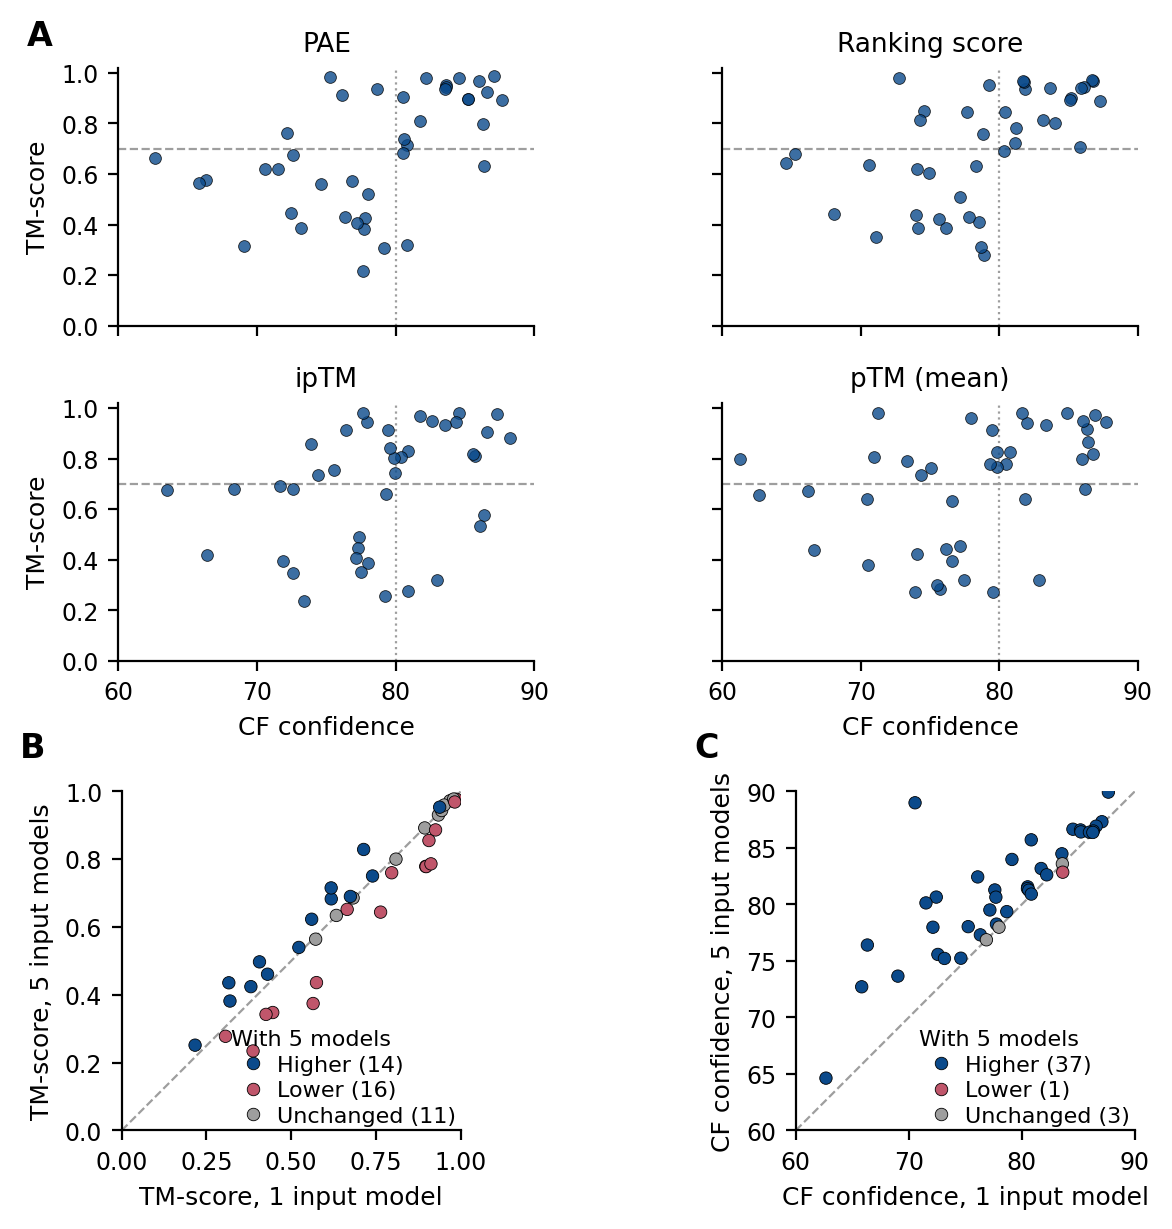

In [10]:
def style_axis(axis):
    axis.spines[["top", "right"]].set_visible(False)


def add_panel_letter(axis, letter, x_offset=-0.25, y_offset=1.08):
    axis.text(x_offset, y_offset, letter, transform=axis.transAxes, fontsize=12, fontweight="bold", va="bottom")


def plot_paired_comparison(axis, values_one_model, values_five_models, axis_limits, delta_label, delta_format):
    delta = values_five_models - values_one_model
    five_higher = delta > TIE_THRESHOLD
    five_lower = delta < -TIE_THRESHOLD
    point_colors = np.where(five_higher, COLOR_FIVE_MODELS_HIGHER, np.where(five_lower, COLOR_FIVE_MODELS_LOWER, NEUTRAL_GREY))
    axis.plot(axis_limits, axis_limits, color=NEUTRAL_GREY, linestyle="--", linewidth=0.8, zorder=0)
    axis.scatter(values_one_model, values_five_models, c=point_colors, s=20, edgecolors="k", linewidths=0.3, zorder=2)
    axis.set_xlim(axis_limits)
    axis.set_ylim(axis_limits)
    axis.set_aspect("equal")
    n_unchanged = len(delta) - five_higher.sum() - five_lower.sum()
    legend_handles = [
        Line2D([], [], marker="o", linestyle="", markersize=4.5, markerfacecolor=marker_color, markeredgecolor="k",
               markeredgewidth=0.3, label=f"{legend_label} ({count})")
        for marker_color, legend_label, count in [
            (COLOR_FIVE_MODELS_HIGHER, "Higher", five_higher.sum()),
            (COLOR_FIVE_MODELS_LOWER, "Lower", five_lower.sum()),
            (NEUTRAL_GREY, "Unchanged", n_unchanged),
        ]
    ]
    axis.legend(handles=legend_handles, loc="lower right", frameon=False, handletextpad=0.1, borderaxespad=0.1,
                borderpad=0.1, labelspacing=0.25, fontsize=ANNOTATION_FONT_SIZE, title="With 5 models",
                title_fontsize=ANNOTATION_FONT_SIZE, alignment="left")
    #axis.set_title(f"n = {len(delta)}, mean {delta_label} {delta.mean():{delta_format}}", fontsize=ANNOTATION_FONT_SIZE + 0.5)
    return int(five_higher.sum()), int(five_lower.sum()), float(delta.mean())


METRIC_PANEL_ASPECT = 0.62  # height / width of the metric panels
figure = plt.figure(figsize=(7.5, 6.9))
outer_grid = GridSpec(2, 1, figure=figure, height_ratios=[1.75, 1], hspace=0.28)
metric_grid = outer_grid[0].subgridspec(2, 2, hspace=0.3, wspace=0.08)
input_number_grid = outer_grid[1].subgridspec(1, 2, wspace=0.38)

# A, confidence vs TM-score per selection metric
all_metric_confidences = np.concatenate([frame["CF_confidence"].to_numpy() for frame in assemblies_by_metric.values()])
metric_confidence_limits = (np.floor(all_metric_confidences.min() / 5) * 5, np.ceil(all_metric_confidences.max() / 5) * 5)
metric_axes = []
for grid_index, (metric, metric_assemblies) in enumerate(assemblies_by_metric.items()):
    row_index, column_index = divmod(grid_index, 2)
    share_axis = metric_axes[0] if metric_axes else None
    metric_axis = figure.add_subplot(metric_grid[row_index, column_index], sharex=share_axis, sharey=share_axis)
    metric_axes.append(metric_axis)
    summary = summarize_metric(metric_assemblies)

    metric_axis.axhline(TM_THRESHOLD, color=NEUTRAL_GREY, linestyle="--", linewidth=0.8, zorder=0)
    metric_axis.axvline(CONFIDENCE_THRESHOLD, color=NEUTRAL_GREY, linestyle=":", linewidth=0.8, zorder=0)
    metric_axis.scatter(metric_assemblies["CF_confidence"], metric_assemblies["usalign_cpx_tm_score"],
                        s=18, color=METRIC_COLORS[metric], alpha=0.8, edgecolors="k", linewidths=0.3)
    # statistics between title and axes, so they never cover data points
    metric_axis.set_box_aspect(METRIC_PANEL_ASPECT)
    metric_axis.set_title(METRIC_LABELS[metric])
    if row_index == 1:
        metric_axis.set_xlabel("CF confidence")
    else:
        metric_axis.tick_params(labelbottom=False)
    if column_index == 0:
        metric_axis.set_ylabel("TM-score")
    else:
        metric_axis.tick_params(labelleft=False)
    style_axis(metric_axis)
metric_axes[0].set_xlim(metric_confidence_limits)
metric_axes[0].set_ylim(0, 1.02)
metric_axes[0].set_yticks(np.arange(0, 1.01, 0.2))
add_panel_letter(metric_axes[0], "A", x_offset=-0.22, y_offset=1.06)

# B, C, 1 vs 5 input models
axis_input_tm = figure.add_subplot(input_number_grid[0, 0])
axis_input_confidence = figure.add_subplot(input_number_grid[0, 1])
input_confidence_limits = (
    np.floor(min(confidence_one_model.min(), confidence_five_models.min()) / 5) * 5,
    np.ceil(max(confidence_one_model.max(), confidence_five_models.max()) / 5) * 5,
)
tm_counts = plot_paired_comparison(axis_input_tm, tm_one_model, tm_five_models, (0, 1), "ΔTM", "+.3f")
confidence_counts = plot_paired_comparison(axis_input_confidence, confidence_one_model, confidence_five_models,
                                           input_confidence_limits, "Δconfidence", "+.2f")
axis_input_tm.set_xlabel("TM-score, 1 input model")
axis_input_tm.set_ylabel("TM-score, 5 input models")
axis_input_confidence.set_xlabel("CF confidence, 1 input model")
axis_input_confidence.set_ylabel("CF confidence, 5 input models")
for axis, panel_letter in [(axis_input_tm, "B"), (axis_input_confidence, "C")]:
    style_axis(axis)
    add_panel_letter(axis, panel_letter, x_offset=-0.3, y_offset=1.08)

plt.show()
figure.savefig("cf_input_model_selection.pdf", bbox_inches="tight")

## 4. Agreement of the picked samples between metrics

Picks per metric come from the selection simulation in `select_best_metric_for_input_models`. A pick is ambiguous if another sample of the same pair has the same metric value (`other_options`), which is frequent for ipTM and pTM. To compare the metrics on the same pairs, only pairs with an unambiguous pick for all four metrics are used.

In [10]:
SELECTION_FILES = {
    "pae": "selection_pae.csv",
    "ranking_score": "selection_ranking_score.csv",
    "iptm": "selection_iptm.csv",
    "ptm_avg": "selection_ptm_avg.csv",
}
REQUIRED_SELECTION_COLUMNS = {"pair_id", "model_uid", "status", "model_rank", "other_options"}

selections_by_metric = {}
for metric, file_name in SELECTION_FILES.items():
    selection_csv = SELECTION_DIR / file_name
    assert selection_csv.exists(), f"missing {selection_csv}"
    metric_selection = pl.read_csv(selection_csv)
    missing_columns = REQUIRED_SELECTION_COLUMNS - set(metric_selection.columns)
    assert not missing_columns, f"{file_name}: missing columns {missing_columns}"
    selections_by_metric[metric] = metric_selection.filter((pl.col("status") == "found") & (pl.col("model_rank") == 1))

# pairs whose top pick is duplicated over chain copies of the same AF3 sample (multi-copy pooled inputs)
chain_copy_pair_ids = set()
for metric_picks in selections_by_metric.values():
    duplicated_picks = metric_picks.group_by("pair_id", "model_uid").len().filter(pl.col("len") > 1)
    chain_copy_pair_ids |= set(duplicated_picks["pair_id"])
print(f"excluding {len(chain_copy_pair_ids)} pairs with chain-copy duplicates")

unambiguous_picks_by_metric = {
    metric: metric_picks.filter(~pl.col("other_options") & ~pl.col("pair_id").is_in(list(chain_copy_pair_ids)))
    for metric, metric_picks in selections_by_metric.items()
}
for metric, metric_picks in unambiguous_picks_by_metric.items():
    assert metric_picks["pair_id"].is_unique().all(), f"{metric}: more than one pick per pair"
    print(f"{METRIC_LABELS[metric]:<14} {selections_by_metric[metric]['pair_id'].n_unique()} pairs, {metric_picks.height} unambiguous")

common_pair_ids = set.intersection(*[set(metric_picks["pair_id"]) for metric_picks in unambiguous_picks_by_metric.values()])
assert common_pair_ids, "no pair is unambiguous for all metrics"
picked_samples_by_metric = {
    METRIC_LABELS[metric]: set(metric_picks.filter(pl.col("pair_id").is_in(list(common_pair_ids))).select("pair_id", "model_uid").iter_rows())
    for metric, metric_picks in unambiguous_picks_by_metric.items()
}
for metric_label, picked_samples in picked_samples_by_metric.items():
    assert len(picked_samples) == len(common_pair_ids), f"{metric_label}: {len(picked_samples)} picks for {len(common_pair_ids)} pairs"

n_same_pick_all_metrics = len(set.intersection(*picked_samples_by_metric.values()))
print(f"\n{len(common_pair_ids)} pairs unambiguous for all metrics, "
      f"{n_same_pick_all_metrics} ({n_same_pick_all_metrics / len(common_pair_ids):.0%}) with the same sample picked by all four")
pae_picks = picked_samples_by_metric[METRIC_LABELS["pae"]]
for metric_label, picked_samples in picked_samples_by_metric.items():
    print(f"same pick as PAE, {metric_label:<14} {len(picked_samples & pae_picks) / len(common_pair_ids):.0%}")

excluding 19 pairs with chain-copy duplicates
PAE            6368 pairs, 6201 unambiguous
Ranking score  6368 pairs, 6349 unambiguous
ipTM           6368 pairs, 2143 unambiguous
pTM (mean)     6368 pairs, 2807 unambiguous

937 pairs unambiguous for all metrics, 29 (3%) with the same sample picked by all four
same pick as PAE, PAE            100%
same pick as PAE, Ranking score  17%
same pick as PAE, ipTM           67%
same pick as PAE, pTM (mean)     16%


## 5. Supplementary figure

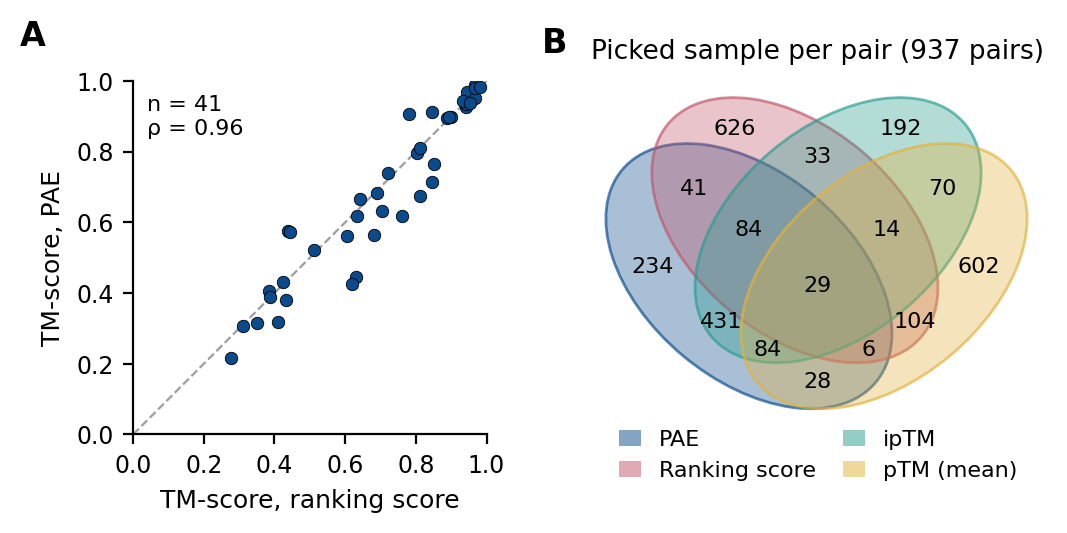

In [12]:
tm_pae_vs_ranking = assemblies_by_metric["pae"].select("complex_ac", tm_pae="usalign_cpx_tm_score").join(
    assemblies_by_metric["ranking_score"].select("complex_ac", tm_ranking="usalign_cpx_tm_score"),
    on="complex_ac", how="inner",
)
tm_rho_pae_vs_ranking = stats.spearmanr(tm_pae_vs_ranking["tm_ranking"], tm_pae_vs_ranking["tm_pae"])[0]

supplementary_figure, (axis_tm_agreement, axis_venn) = plt.subplots(
    1, 2, figsize=(TEXTWIDTH_INCHES, 3.3), gridspec_kw={"width_ratios": [1, 1.3], "wspace": 0.25}
)

# A, TM-scores of PAE- vs ranking-score-picked assemblies
axis_tm_agreement.plot((0, 1), (0, 1), color=NEUTRAL_GREY, linestyle="--", linewidth=0.8, zorder=0)
axis_tm_agreement.scatter(tm_pae_vs_ranking["tm_ranking"], tm_pae_vs_ranking["tm_pae"],
                          s=20, color=METRIC_COLORS["pae"], edgecolors="k", linewidths=0.3)
axis_tm_agreement.set_xlim(0, 1)
axis_tm_agreement.set_ylim(0, 1)
axis_tm_agreement.set_xticks(np.arange(0, 1.01, 0.2))
axis_tm_agreement.set_yticks(np.arange(0, 1.01, 0.2))
axis_tm_agreement.set_aspect("equal")
axis_tm_agreement.set_xlabel("TM-score, ranking score")
axis_tm_agreement.set_ylabel("TM-score, PAE")
axis_tm_agreement.text(0.04, 0.96, f"n = {tm_pae_vs_ranking.height}\nρ = {tm_rho_pae_vs_ranking:.2f}",
                       transform=axis_tm_agreement.transAxes, va="top", fontsize=ANNOTATION_FONT_SIZE)
style_axis(axis_tm_agreement)
add_panel_letter(axis_tm_agreement, "A", x_offset=-0.32)

# B, agreement of picked samples
draw_four_set_venn(
    picked_samples_by_metric, ax=axis_venn,
    cmap=[METRIC_COLORS[metric] for metric in SELECTION_FILES], alpha=0.35, fontsize=ANNOTATION_FONT_SIZE, legend_loc=None,
)
axis_venn.set_xlim(0.0, 1.0)
axis_venn.set_ylim(0.08, 0.8)
axis_venn.legend(
    handles=[Patch(facecolor=METRIC_COLORS[metric], alpha=0.5, label=METRIC_LABELS[metric]) for metric in SELECTION_FILES],
    loc="upper center", bbox_to_anchor=(0.5, 0.04), ncol=2, frameon=False, handlelength=1, columnspacing=1.2,
)
axis_venn.set_title(f"Picked sample per pair ({len(common_pair_ids)} pairs)", pad=12)
add_panel_letter(axis_venn, "B", x_offset=-0.1, y_offset=1.1)

plt.show()
supplementary_figure.savefig("cf_input_model_selection_supplementary.pdf", bbox_inches="tight")

## 6. Numbers quoted in the text

In [ ]:
print(metric_summary)
print(f"\nSpearman rho TM-score PAE vs ranking score   {tm_rho_pae_vs_ranking:.2f} (n = {tm_pae_vs_ranking.height})")
print(f"1 vs 5 models, TM higher/lower              {tm_counts[0]}/{tm_counts[1]}, mean change {tm_counts[2]:+.3f}")
print(f"1 vs 5 models, confidence higher/lower      {confidence_counts[0]}/{confidence_counts[1]}, mean change {confidence_counts[2]:+.2f}")
print(f"Spearman rho confidence vs TM, 1 model      {stats.spearmanr(confidence_one_model, tm_one_model)[0]:.2f}")
print(f"Spearman rho confidence vs TM, 5 models     {stats.spearmanr(confidence_five_models, tm_five_models)[0]:.2f}")
print(f"TM > {TM_THRESHOLD}, 1 model / 5 models              {(tm_one_model > TM_THRESHOLD).sum()} / {(tm_five_models > TM_THRESHOLD).sum()}")
print(f"same sample picked by all four metrics      {n_same_pick_all_metrics}/{len(common_pair_ids)}")